In [361]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack
import csv
import pandas as pd

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
plt.rcParams['axes.grid'] = True

In [362]:
styrofoam_trial_1_data = pd.read_csv('data/exp3_styrofoam_trial1.gambl.csv')
styrofoam_trial_2_data = pd.read_csv('data/exp3_styrofoam_trial2.gambl.csv')
styrofoam_trial_3_data = pd.read_csv('data/exp3_styrofoam_trial3.gambl.csv')
styrofoam_trial_4_data = pd.read_csv('data/exp3_styrofoam_trial4.gambl.csv')



In [363]:
water_heat_capacity = 4.184 # J g^-1 C^-1
cup_wall_thickness = 2.6
cup_wall_thickness_err = 0.02

cup_bottom_thickness = 2.0
cup_bottom_thickness_err = 0.02

cup_mass = 5.5
cup_mass_err = 0.3


water_mass = np.array([255, 246, 210]) - cup_mass
water_mass_err = np.array([1, 1, 1]) - cup_mass_err

water_slant_height = np.array([81.28, 80.42, 68.92]) - cup_bottom_thickness
water_slant_height_err = np.array([2, 2, 2])

top_radius = np.array([75, 74.50, 74.10])
top_radius_err = np.array([1, 1, 1])
bottom_radius = np.array([61.38, 61.38, 61.38])
bottom_radius_err = np.array([1, 1, 1])

bottom_surface_area = np.pi * bottom_radius**2 # mm^2
side_surface_area = np.pi * (bottom_radius + top_radius) * water_slant_height # mm^2

initial_temp = np.array([8.963, 42.727, 22.641])
initial_temp_err = np.array([0.019, 0.034, 0.087])

bath_temp = np.array([45.063, 16.791, 49.167])
bath_temp_err = np.array([0.015, 0.013, 0.048])



trial_3_start_idx = np.argmin(np.abs(styrofoam_trial_3_data['Data Set 8:Time(s)'] - 90))
trial_3_stop_idx = np.argmin(np.abs(styrofoam_trial_3_data['Data Set 8:Time(s)'] - 300))

styrofoam_trial_times = np.array([
    #styrofoam_trial_1_data['Data Set 22:Time(s)'],
    styrofoam_trial_2_data['Data Set 5:Time(s)'],
    styrofoam_trial_3_data['Data Set 8:Time(s)'][trial_3_start_idx:trial_3_stop_idx] - styrofoam_trial_3_data['Data Set 8:Time(s)'][trial_3_start_idx],
    styrofoam_trial_4_data['Data Set 3:Time(s)']], dtype=pd.Series)



styrofoam_trial_temps = np.array([
    #styrofoam_trial_1_data['Data Set 22:Temperature(°C)'],
    styrofoam_trial_2_data['Data Set 5:Temperature(°C)'],
    styrofoam_trial_3_data['Data Set 8:Temperature(°C)'][trial_3_start_idx:trial_3_stop_idx],
    styrofoam_trial_4_data['Data Set 3:Temperature(°C)']], dtype=pd.Series)

styrofoam_trial_heats = styrofoam_trial_temps * water_mass * water_heat_capacity


In [364]:
i = 2

In [365]:

def linear_fit(t, C, T0):
    return -C * (T0 - bath_temp[i]) * t + T0


def exponential_fit(t, C, T0):
    return (T0 - bath_temp[i]) * np.exp(-1 * C * t) + bath_temp[i]




In [366]:
popt_lin, pcov_lin = scipy.optimize.curve_fit(linear_fit, styrofoam_trial_times[i], styrofoam_trial_temps[i], maxfev=10000, p0=(-1, 10))




C_lin = popt_lin[0]
T0_lin = popt_lin[1]

C_lin_err = np.sqrt(pcov_lin[0][0])
T0_lin_err = np.sqrt(pcov_lin[1][1])
#T_bath_lin = popt_lin[2]

#print(C_lin, T0_lin)


popt_exp, pcov_exp = scipy.optimize.curve_fit(exponential_fit, styrofoam_trial_times[i], styrofoam_trial_temps[i], p0=(C_lin, T0_lin), maxfev=10000)

C_exp = popt_exp[0]
T0_exp = popt_exp[1]

#print(C_exp, T0_exp)

#Conductivity in W m^-1 K^-1
K_lin = 1000 * C_lin * ((cup_wall_thickness / side_surface_area + cup_bottom_thickness / bottom_surface_area) * water_mass * water_heat_capacity)[i]

K_exp = 1000 * C_exp * ((cup_wall_thickness / side_surface_area + cup_bottom_thickness / bottom_surface_area) * water_mass * water_heat_capacity)[i]

print(K_exp)

0.05051557416642372


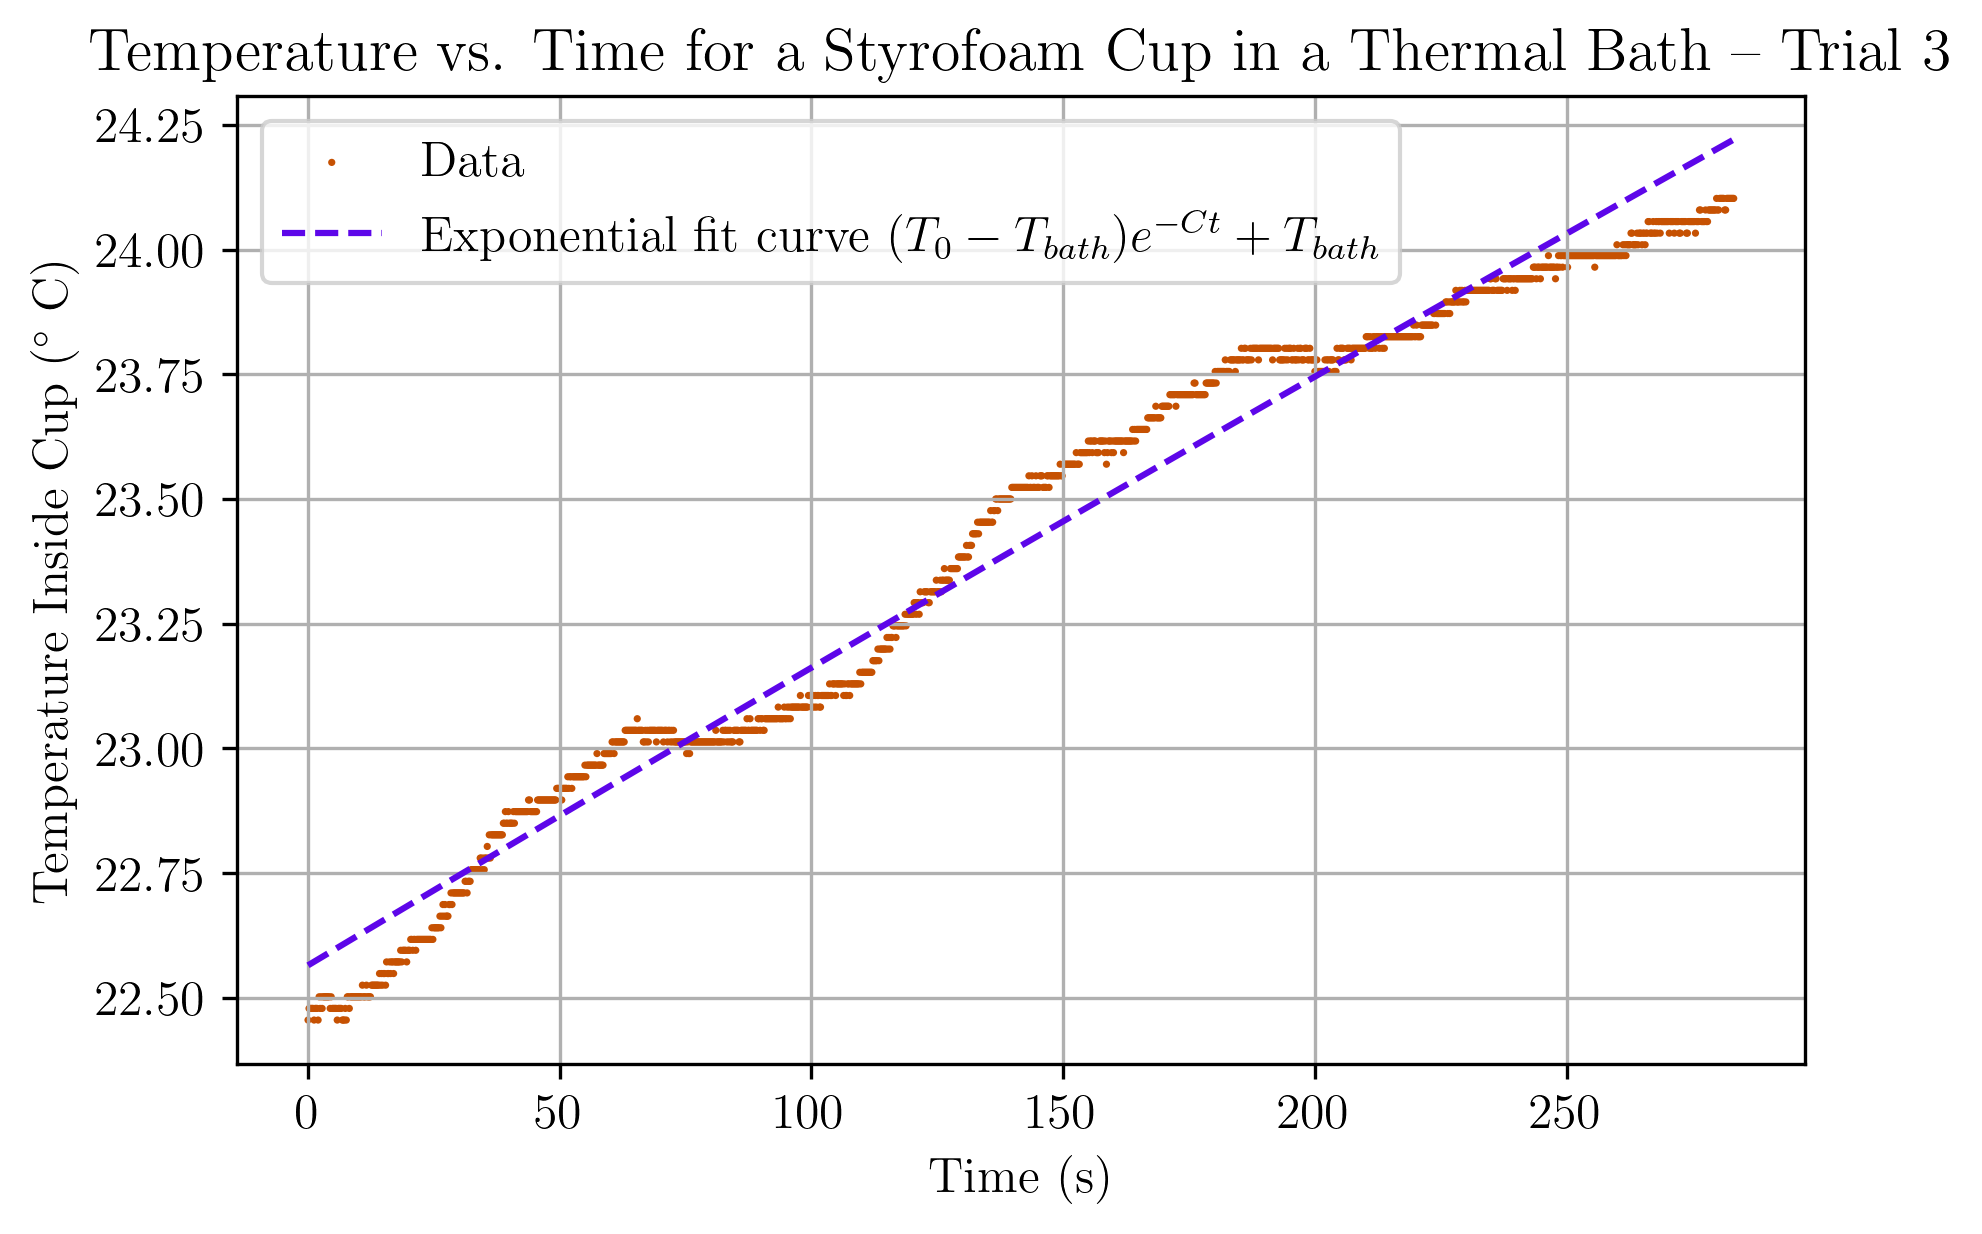

In [367]:
fig, ax = plt.subplots(1, figsize=(6, 4), layout='constrained')

ax.scatter(styrofoam_trial_times[i], styrofoam_trial_temps[i], edgecolors='none', s = 3, color = 'xkcd:dark orange', label = 'Data')

x_vals = np.linspace(0, max(styrofoam_trial_times[i]), 100)

#ax.plot(x_vals, linear_fit(x_vals, C_lin, T0_lin), color = 'blueviolet')

ax.plot(x_vals, exponential_fit(x_vals, C_exp, T0_exp), linestyle = 'dashed', color='xkcd:blue violet',
        label = rf"Exponential fit curve $(T_0 - T_{{bath}})e^{{-Ct}} + T_{{bath}}$")


ax.set_title(f"Temperature vs. Time for a Styrofoam Cup in a Thermal Bath -- Trial {i+1}")
ax.set_xlabel(r"Time (s)")
ax.set_ylabel(r"Temperature Inside Cup ($^\circ$ C)")

ax.legend()